# Email Spam Detection with Machine Learning
**OASIS INFOBYTE — Data Science Internship**  
**Student:** MAYUR R SHETTY

## Objective
Classify labelled messages as spam or ham using NLP and machine learning. The public UCI benchmark used here is the SMS Spam Collection, not an email corpus; this limitation is explicitly documented.

## 1. Import libraries and load dataset
Download UCI SMS Spam Collection if it is not already in `data/`. If download is unavailable, add the extracted `SMSSpamCollection` file to that folder.

In [9]:
from pathlib import Path
import csv, io, json, re, urllib.request, zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

ROOT = Path.cwd()
DATA_DIR, OUTPUT_DIR = ROOT / "data", ROOT / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)
DATA_FILE = DATA_DIR / "SMSSpamCollection"
urls = [
    "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip",
    "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
]
if not DATA_FILE.exists():
    errors = []
    for url in urls:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, timeout=30) as response:
                content = response.read()
            if url.endswith(".zip"):
                with zipfile.ZipFile(io.BytesIO(content)) as archive:
                    member = next(n for n in archive.namelist() if n.endswith("SMSSpamCollection"))
                    DATA_FILE.write_bytes(archive.read(member))
            else:
                DATA_FILE.write_bytes(content)
            break
        except Exception as exc:
            errors.append(str(exc))
    if not DATA_FILE.exists():
        raise RuntimeError("Download UCI SMS Spam Collection and place SMSSpamCollection in data/. " + " | ".join(errors))

try:
    data = pd.read_csv(DATA_FILE, sep="\\t", header=None, names=["label", "message"],
                       quoting=csv.QUOTE_NONE, encoding="utf-8")
except UnicodeDecodeError:
    data = pd.read_csv(DATA_FILE, sep="\\t", header=None, names=["label", "message"],
                       quoting=csv.QUOTE_NONE, encoding="latin-1")
if len(data) and str(data.iloc[0]["label"]).lower() in {"label", "v1"}:
    data = data.iloc[1:].copy()
data["label"] = data["label"].astype(str).str.strip().str.lower()
data["message"] = data["message"].astype(str).str.strip()
data = data[data["label"].isin(["ham", "spam"])].drop_duplicates().reset_index(drop=True)
display(data.head())
print("Dataset shape:", data.shape)

/tmp/ipykernel_3009/3289682086.py:44: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  data = pd.read_csv(DATA_FILE, sep="\\t", header=None, names=["label", "message"],


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Dataset shape: (5160, 2)


## 2. Class distribution and data inspection
Check spam/ham counts and percentages, and inspect missing values.

Class counts:


,count
label,
ham,4518
spam,642


Class percentages:


,percentage
label,
ham,87.56
spam,12.44


Missing values:


,missing values
label,0
message,0


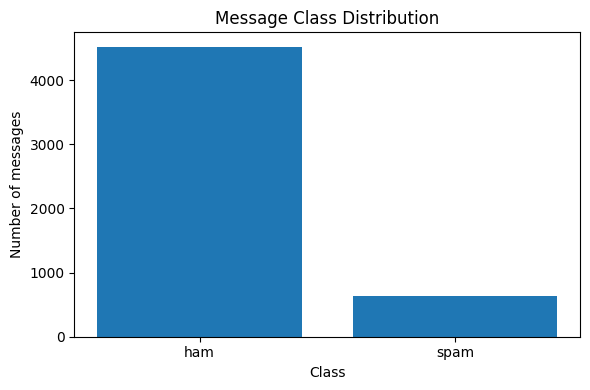

In [10]:
print("Class counts:")
display(data["label"].value_counts().to_frame("count"))
print("Class percentages:")
display((data["label"].value_counts(normalize=True) * 100).round(2).to_frame("percentage"))
print("Missing values:")
display(data.isna().sum().to_frame("missing values"))
counts = data["label"].value_counts().reindex(["ham", "spam"])
plt.figure(figsize=(6, 4))
plt.bar(counts.index, counts.values)
plt.title("Message Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of messages")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=160)
plt.show()

## 3. Text preprocessing
Steps: lowercase conversion, URL replacement, punctuation/symbol removal, and whitespace normalization. Stopword removal is performed by TF-IDF. Stemming/lemmatization is optional and is not required for this baseline.

In [11]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\\S+|www\\.\\S+", " URL ", text)
    text = re.sub(r"[^a-z0-9\\s]", " ", text)
    text = re.sub(r"\\s+", " ", text).strip()
    return text

data["clean_message"] = data["message"].map(clean_text)
data = data[data["clean_message"].str.len() > 0].reset_index(drop=True)
display(data[["message", "clean_message", "label"]].head(8))

,message,clean_message,label
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only ...,ham
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...,spam
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,ham
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives aro...,ham
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling it s been 3 week s n...,spam
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me ...,ham
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnamin...,ham


## 4. TF-IDF feature extraction
TF-IDF (Term Frequency–Inverse Document Frequency) gives higher weight to terms that are frequent in a message but less common across the full corpus. The vectorizer is placed inside each model pipeline so it learns vocabulary from training data only.

## 5. Train/test split and classifiers
Use a stratified 80/20 split. Train Multinomial Naive Bayes and Logistic Regression.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    data["clean_message"], data["label"], test_size=0.20,
    random_state=42, stratify=data["label"]
)
models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2),
                                  min_df=2, max_df=0.98, sublinear_tf=True)),
        ("classifier", MultinomialNB(alpha=0.5))
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2),
                                  min_df=2, max_df=0.98, sublinear_tf=True)),
        ("classifier", LogisticRegression(max_iter=1500, class_weight="balanced",
                                          random_state=42))
    ])
}
metrics, fitted, predictions = {}, {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted[name], predictions[name] = model, pred
    metrics[name] = {
        "accuracy": accuracy_score(y_test, pred),
        "precision_spam": precision_score(y_test, pred, pos_label="spam", zero_division=0),
        "recall_spam": recall_score(y_test, pred, pos_label="spam", zero_division=0),
        "f1_spam": f1_score(y_test, pred, pos_label="spam", zero_division=0),
        "precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_test, pred, average="macro", zero_division=0)
    }
metric_df = pd.DataFrame(metrics).T
display(metric_df.round(4))

,accuracy,precision_spam,recall_spam,f1_spam,precision_macro,recall_macro,f1_macro
Multinomial Naive Bayes,0.9787,0.9907,0.8359,0.9068,0.9840,0.9174,0.9474
Logistic Regression,0.9787,0.9015,0.9297,0.9154,0.9458,0.9577,0.9516


## 6. Model evaluation
Review accuracy, spam precision, spam recall, spam F1, and confusion matrices. Spam recall is important because low recall means actual spam messages are missed. Precision matters too because low precision means legitimate messages are incorrectly flagged.

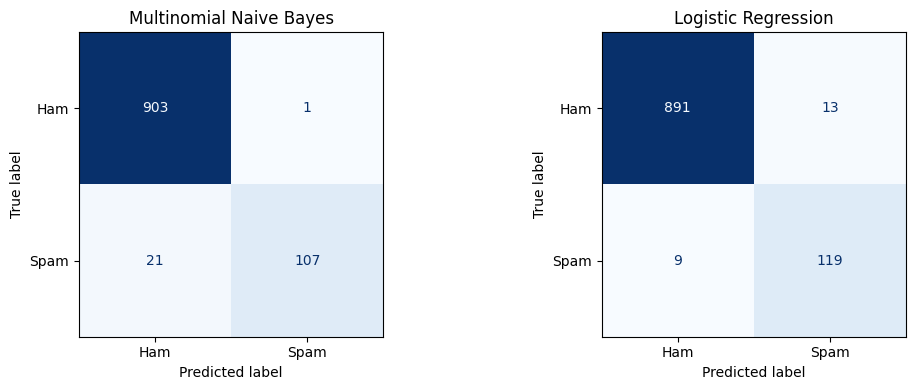

\n Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham       0.98      1.00      0.99       904
        spam       0.99      0.84      0.91       128

    accuracy                           0.98      1032
   macro avg       0.98      0.92      0.95      1032
weighted avg       0.98      0.98      0.98      1032

\n Logistic Regression
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       904
        spam       0.90      0.93      0.92       128

    accuracy                           0.98      1032
   macro avg       0.95      0.96      0.95      1032
weighted avg       0.98      0.98      0.98      1032



In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=["ham", "spam"], display_labels=["Ham", "Spam"],
        cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "confusion_matrices.png", dpi=160)
plt.show()

for name, pred in predictions.items():
    print("\\n", name)
    print(classification_report(y_test, pred, labels=["ham", "spam"],
                                target_names=["ham", "spam"], zero_division=0))

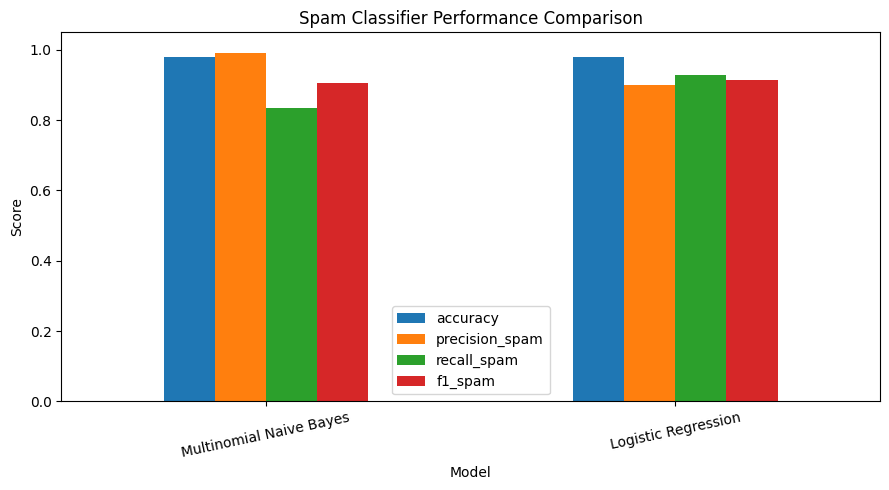

In [14]:
ax = metric_df[["accuracy", "precision_spam", "recall_spam", "f1_spam"]].plot(
    kind="bar", figsize=(9, 5)
)
ax.set_ylim(0, 1.05)
ax.set_title("Spam Classifier Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=12)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_comparison.png", dpi=160)
plt.show()

## 7. Optional common-term visualizations
These charts show terms with the largest summed TF-IDF weights in each class. They are descriptive, not a causal explanation of why a message is spam.

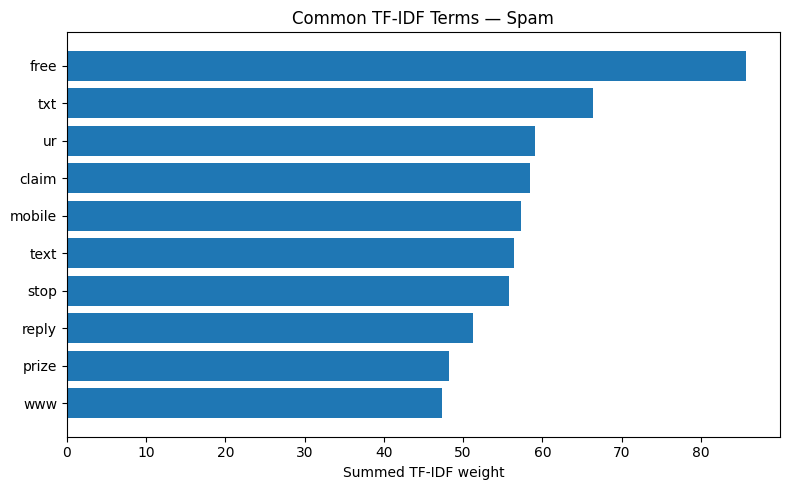

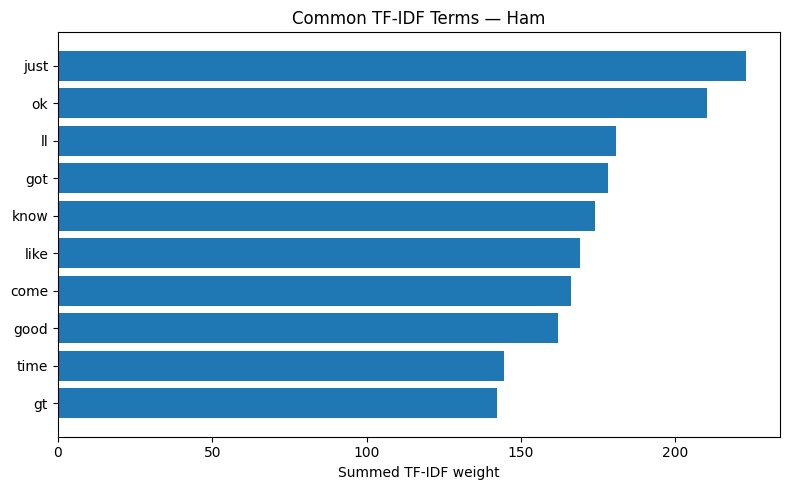

In [15]:
for label in ["spam", "ham"]:
    subset = data.loc[data["label"] == label, "clean_message"]
    vectorizer = TfidfVectorizer(stop_words="english", max_features=15)
    matrix = vectorizer.fit_transform(subset)
    totals = np.asarray(matrix.sum(axis=0)).ravel()
    terms = np.array(vectorizer.get_feature_names_out())
    order = np.argsort(totals)[-10:]
    plt.figure(figsize=(8, 5))
    plt.barh(terms[order], totals[order])
    plt.title(f"Common TF-IDF Terms — {label.title()}")
    plt.xlabel("Summed TF-IDF weight")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"common_terms_{label}.png", dpi=160)
    plt.show()

## 8. Select and save model
The selection rule prioritizes spam recall, then spam F1, then accuracy. Inspect precision and the confusion matrix alongside this rule.

In [16]:
best_name = max(metrics, key=lambda name: (
    metrics[name]["recall_spam"], metrics[name]["f1_spam"], metrics[name]["accuracy"]
))
best_model = fitted[best_name]
best_pred = predictions[best_name]
print("Selected model:", best_name)
print(classification_report(y_test, best_pred, labels=["ham", "spam"],
                            target_names=["ham", "spam"], zero_division=0))
joblib.dump(best_model, OUTPUT_DIR / "best_spam_classifier.joblib")
report = classification_report(y_test, best_pred, labels=["ham", "spam"],
                               target_names=["ham", "spam"], output_dict=True, zero_division=0)
results = {
    "student": "MAYUR R SHETTY",
    "dataset_rows": len(data),
    "class_counts": data["label"].value_counts().to_dict(),
    "model_metrics": metric_df.to_dict(orient="index"),
    "selected_model": best_name,
    "classification_report": report
}
(OUTPUT_DIR / "results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print("Saved model and metrics to:", OUTPUT_DIR.resolve())

Selected model: Logistic Regression
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       904
        spam       0.90      0.93      0.92       128

    accuracy                           0.98      1032
   macro avg       0.95      0.96      0.95      1032
weighted avg       0.98      0.98      0.98      1032

Saved model and metrics to: /content/outputs


## 9. Conclusion and limitations
This project trains two NLP classifiers and evaluates their ability to identify spam. Recall is important because missed spam can reach the inbox; precision is also important because legitimate messages should not be blocked unnecessarily.

**Dataset limitation:** The public UCI collection used here contains SMS messages, not emails. The model demonstrates a spam/ham text-classification workflow, but should not be represented as trained on actual email data. For a real email classifier, retrain and validate on an email dataset.

**Before submission:** Run every cell, inspect your actual results, add your own screenshots, and record a live demo.